# 08 - Innovation: the Fair Price Checker
Compares the advertised phone price with the price predicted by the selected machine learning model. It classifies advertisements as Good Deal, Fair Price or Overpriced based on the percentage difference. This feature helps buyers identify potentially attractive prices and helps sellers understand competitive pricing.

`difference = asking / predicted - 1`  ->  **Good deal** (below -tolerance) | **Fair price** (within +-tolerance) | **Overpriced** (above +tolerance)




In [ ]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from src import predict as PR
import joblib
preds = pd.read_csv(config.OUT_DIR / "test_predictions.csv")
test_df = pd.read_csv(config.OUT_DIR / "model_comparison.csv")
best_name = (config.OUT_DIR / "best_model.txt").read_text()
print("fair-price model (best on validation):", best_name)

fair-price model (best on validation): Hybrid (RF + ANN)


## 1. Scan every test listing 
(these rows were never used for training)
Each test listing is compared with its predicted fair price using the selected model. A 15% tolerance is used to classify listings as Good Deal, Fair Price or Overpriced. The distribution of price differences is also visualised to understand how advertised prices differ from predicted prices.

In [3]:
TOL = 0.15
scan = PR.scan_listings(preds, best_name, TOL)
print(scan["verdict"].value_counts())
print("median difference: %.1f%%" % scan["difference_%"].median())
mape = test_df.loc[test_df["Model"] == best_name, "MAPE_%"].iloc[0]
print("typical model error (MAPE): %.1f%%  -> tolerance used: %.0f%%" % (mape, TOL * 100))

verdict
Fair price    411
Overpriced    128
Good deal     126
Name: count, dtype: int64
median difference: 0.5%
typical model error (MAPE): 32.8%  -> tolerance used: 15%


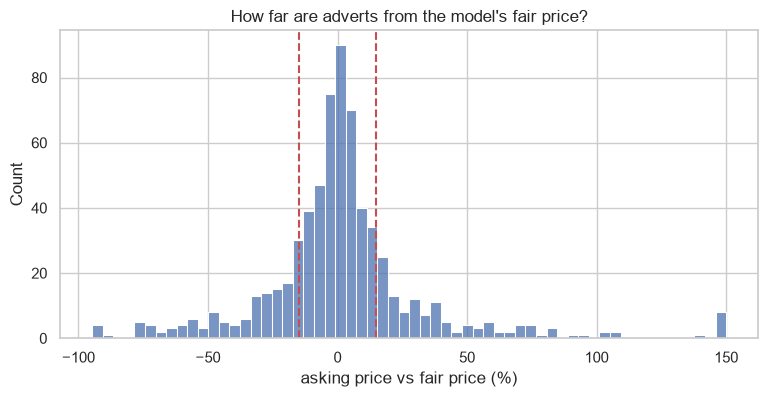

In [4]:
plt.figure(figsize=(9, 4))
sns.histplot(scan["difference_%"].clip(-100, 150), bins=60, color="#4C72B0")
for x in (-TOL * 100, TOL * 100): plt.axvline(x, color="r", ls="--")
plt.xlabel("asking price vs fair price (%)"); plt.title("How far are adverts from the model's fair price?")
plt.savefig(config.PLOT_DIR / "08_difference_distribution.png", dpi=150); plt.show()

## 2. Who is over- or under-priced?
compares the percentage of Good Deal, Fair Price and Overpriced listings across different data sources and phone conditions. It helps identify pricing patterns between these groups.

In [5]:
pd.crosstab(scan["source"], scan["verdict"], normalize="index").round(3) * 100

verdict,Fair price,Good deal,Overpriced
source,,,
Dialog,50.00,33.30,16.70
ikman,61.90,18.80,19.30


In [6]:
pd.crosstab(scan["condition"], scan["verdict"], normalize="index").round(3) * 100

verdict,Fair price,Good deal,Overpriced
condition,,,
Brand New,67.60,14.50,17.90
Used,59.80,20.50,19.70


## 3. Examples

In [7]:
cols = [c for c in ["title", "source", "condition", "location", "price", "fair_price", "difference_%", "verdict"] if c in scan.columns]
print("Biggest potential bargains:"); display(scan.sort_values("difference_%")[cols].head(8)) if "display" in globals() else print(scan.sort_values("difference_%")[cols].head(8))
print("Most over-priced:"); display(scan.sort_values("difference_%", ascending=False)[cols].head(8)) if "display" in globals() else print(scan.sort_values("difference_%", ascending=False)[cols].head(8))

Biggest potential bargains:
                                   title source  condition     location  \
407               Apple iPhone 5S (Used)  ikman       Used        Kandy   
17              Samsung Galaxy S2 (Used)  ikman       Used        Kandy   
342           Sky i21 Keypad Phone (New)  ikman  Brand New      Gampaha   
133            Samsung B310E Used (Used)  ikman       Used   Kurunegala   
175  Apple iPhone 18 Pro Max (Brand New)  ikman  Brand New      Gampaha   
546         Samsung Galaxy J7 max (Used)  ikman       Used    Ratnapura   
98    Honor 400 Pro 12/512GB (Brand New)  ikman  Brand New      Colombo   
356             Samsung Galaxy J2 (Used)  ikman       Used  Polonnaruwa   

     price  fair_price  difference_%    verdict  
407   5000   95,042.99        -94.74  Good deal  
17    2300   32,356.86        -92.89  Good deal  
342   2990   38,906.61        -92.31  Good deal  
133   1500   17,110.90        -91.23  Good deal  
175  35000  367,040.95        -90.46  Good dea

## 4. Sensitivity to the tolerance
A tolerance below the model's typical error flags many adverts by chance; a very large tolerance flags almost nothing.

In [8]:
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    v = PR.scan_listings(preds, best_name, t)["verdict"].value_counts(normalize=True)
    rows.append({"tolerance_%": int(t * 100), **{k: round(v.get(k, 0) * 100, 1) for k in PR.VERDICTS}})
pd.DataFrame(rows)

,tolerance_%,Good deal,Fair price,Overpriced
0,5,34.60,29.80,35.60
1,10,25.90,47.80,26.30
2,15,18.90,61.80,19.20
3,20,15.50,69.30,15.20
4,25,12.60,74.70,12.60
5,30,10.10,78.60,11.30


## 5. One Advertisement – Complete Process

A sample advertisement is selected from the cleaned dataset. Its phone details are passed to the trained model to predict a fair price. The asking price is then compared with the predicted price to generate a verdict. This demonstrates how the Fair Price Checker works in the dashboard.

In [9]:
model = joblib.load(config.MODEL_DIR / "best_model.pkl")
clean = pd.read_csv(config.CLEAN_CSV)
ad = clean.sample(1, random_state=7).iloc[0]
row = PR.make_input(ad["brand"], ad["model"], ad["condition"], ad["storage_gb"], ad["ram_gb"], ad["location"], ad["source"])
fair = float(model.predict(row)[0])
verdict, diff = PR.deal_verdict(ad["price"], fair, TOL)
print(f"{ad['title']}\nasking Rs. {ad['price']:,.0f} | fair price Rs. {fair:,.0f} | {diff * 100:+.1f}% -> {verdict}")
print("(this row may have been in the training data; use the test-set scan above for honest numbers)")

Moto Edge 60 Fusion 256GB (Used)
asking Rs. 62,000 | fair price Rs. 44,954 | +37.9% -> Overpriced
(this row may have been in the training data; use the test-set scan above for honest numbers)


## 6. Limitations
- **Model accuracy:** MAPE is about 33%, so small price differences may not be reliable.
- **Extreme predictions:** Old, rare and unusual phone models can receive unrealistic predictions.
- **Missing information:** The model cannot identify phone damage, battery health, accessories or warranty.
- **Price differences:** ikman has negotiable asking prices, while Dialog has retail catalogue prices.
- **Limited data:** Only 6 Dialog listings were in the test set, making their results unreliable.
- **No ground truth:** Good-deal predictions cannot be fully verified, so the checker is only a guide, not a guarantee.